Dorothee MG

Study: Validation of empathy videos\
Perceivers watch videos of targets talking about emotional life events. \
Perceivers rate the video on a continuous scale through time. \
We have ECG data from targets (while they talk) and from perceivers (while they watch) 
    
Videos are about 2min long\
We have 5 videos for each emotion

Goal: \
#1 Clean ECG data (e.g., remove artefactual areas, ectopic heart beats, etc.)\
#2 Graph data
    

In [1]:

# libraries

import json
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore


Prepare lists to use later

In [2]:

# targets
targets = ['P03_joy', 'P29_joy', 'P34_joy', 'P42_joy', 'P44_joy',
           'P12_sadness', 'P15_sadness', 'P27_sadness', 'P34_sadness', 'P44_sadness', 
           'P03_anger', 'P15_anger', 'P22_anger', 'P38_anger', 'P42_anger',
           'P17_pride', 'P22_pride', 'P29_pride', 'P42_pride', 'P44_pride',
           'P03_shame', 'P22_shame', 'P37_shame', 'P38_shame', 'P45_shame', 
           'P12_neutral', 'P17_neutral', 'P29_neutral', 'P34_neutral', 'P38_neutral']

# perceivers
perceivers = ["S01", "S02", "S03", "S04", "S05", "S06", "S07", "S08", "S11", "S15", "S18", "S20", "S23",
              "S24", "S28", "S34", "S37", "S42", "S44", "S45", "S47", "S49", "S51", "S54", "S55", "S57", "S64", "S65"]

# data folders
data_folder = r"physiological_data"


Functions to clean the data -> exclude 'invalid areas' (artefactual) and calculate R-R intervals

Also smooth the data with a 10s rolling window (method: mean)

In [3]:
# helper functions

# determines if two intervals overlap (from biotop) => this will help to remove invalid areas (e.g., artefacts) from data (later)
def does_overlap(intv1, intv2):
    (a1, b1) = intv1
    if a1 > b1: (a1, b1) = (b1, a1)
    (a2, b2) = intv2
    if a2 > b2: (a2, b2) = (b2, a2)
    overlapmin = max([a1, a2])
    overlapmax = min([b1, b2])
    return overlapmin <= overlapmax # true if overlap

# filter out any interval overlapping with invalid area
def exclude_invalid(peak_times, invalid_areas):
    valid_intervals = []
    for i in range(len(peak_times) - 1):  # -1 so it does not go out of range
        start_time = peak_times[i]  # peak 1
        end_time = peak_times[i + 1]  # peak 2
        interval = (start_time, end_time)
        if any(does_overlap(interval, invalid_area) for invalid_area in invalid_areas):
            valid_intervals.append((start_time, np.nan)) # nan to break the line *******
        else:
            valid_intervals.append(interval)  # if not overlap with invalid area, add to list
    return valid_intervals

# define peak times and RR intervals
def calculate_valid_RRs(ecg_data, label):
    peak_times = np.array([data['t'] for data in ecg_data['peaks'][label]]) # identify peak times
    peak_times.sort() # sort in order
    invalid_areas = [(data['start'], data['end']) for data in ecg_data['invalid'][label]] # identify invalid areas
    valid_intervals = exclude_invalid(peak_times, invalid_areas) # exclude invalid
    time_diffs = [end - start if ecg_data['peaks'][label][i]['valid'] and
                  ecg_data['peaks'][label][i-1]['valid'] else None
                  for i, (start, end) in enumerate(valid_intervals)] # identify RR intervals
    peak_times = peak_times[:min(len(peak_times[:-1]), len(time_diffs))]   # peaks - 1 so n peaks = n intervals (otherwise later code does not work properly; maybe there is a better solution?)
    time_diffs = np.array([np.nan if x is None else x for x in time_diffs]) # convert 'none' to 'nan' (useful for correlations later)
    return peak_times, time_diffs # return list of peaks (peak_times) and RR intervals (time_diffs)

# load ECG data from JSON
def load_ecg_data(file_path):
    try:
        with open(file_path, 'r') as file:
            return json.load(file)
    except FileNotFoundError:
        return {} # just in case

# clean perceiver ECG data => separate from target cleaning, because different structure (file name, channel name, etc.)
def clean_perceiver_ecg(data_folder, perceiver_id, target):
    perceiver_file = os.path.join(data_folder, f"{perceiver_id}_{target}_peaks.json") # open perceiver file
    if not os.path.exists(perceiver_file):
        return [], [] # (perceivers did not watch all targets) 
    ecg_data_perceiver = load_ecg_data(perceiver_file)
    peak_times_perceiver, time_diffs_perceiver = calculate_valid_RRs(ecg_data_perceiver, "ECG, X, RSPEC-R") # calculate RR intervals
    return peak_times_perceiver, time_diffs_perceiver

# clean target ECG data => ** I should combine this with clean_perceiver_ecg at some point
def clean_target_ecg(data_folder, target):
    target_file = os.path.join(data_folder, f"{target}_peaks.json") # open target file
    ecg_data_target = load_ecg_data(target_file)
    target_id = target.split('_')[0] # take target number (before the '_'), not whole video name
    peak_times_target, time_diffs_target = calculate_valid_RRs(ecg_data_target, f"ECG {target_id}") # calculate RR intervals
    return peak_times_target, time_diffs_target

# sliding window of 10s for HRV => but there is less data at the extremities so I'm not sure this works 100%
def sliding_window_mean(peak_times, values):

    averaged_peak_times = []
    averaged_time_diffs = []
    half_window = 5  # half of the 10s window (5s before, 5s after)

    for peak in peak_times:
        start_time, end_time = peak - half_window, peak + half_window # define the window
        window_values = values[(peak_times >= start_time) & (peak_times <= end_time)] # extract values that fall within the window
        if len(window_values) > 0:  # avoid empty (just in case)
            averaged_peak_times.append(peak)
            averaged_time_diffs.append(np.nanmean(window_values))  # compute mean ignoring nan

    return averaged_peak_times, averaged_time_diffs


Visualize data, and at the same time explore different strategies of ectopic beat detection. 


RR-intervals: [0.8595 0.899  0.909  0.8485 0.9255 0.948  0.912  0.89   0.95   1.0075
 0.8895 0.9575 0.989  0.919  0.9215 0.985  0.9995 0.914  0.978  0.9935
 0.946  0.9315 1.028  1.0505 0.939  1.033  1.0985 0.9675 1.0285 1.0395
 0.926  0.9515 1.     0.9765 0.901  0.9555 0.981  0.9185 0.8565 0.8995
 0.921  0.85   0.9105 0.909  0.977  0.973  0.913  0.919  0.903  0.822
 0.8125 0.886  0.973  1.0255 1.0665 1.0745 1.1075 1.0815 1.0045 0.9215
 0.932  0.946  0.972  0.9035 0.9235 0.986  0.972  0.8835 0.953  0.9885
 1.032  0.9425 0.988  1.027  0.9555 0.8965 0.9415 0.9695 0.874  0.9585
 0.998  0.9295 0.9425 0.9645 0.941  0.867  0.9145 0.91   0.849  0.8465
 0.8885 0.8755 0.8495 0.9145 0.911  0.8675 0.8475 0.892  0.9335 0.851
 0.912  0.9455 0.9025 0.87   0.9255 0.92   0.867  0.8855 0.8535 0.8835
 0.9065 0.897 ]


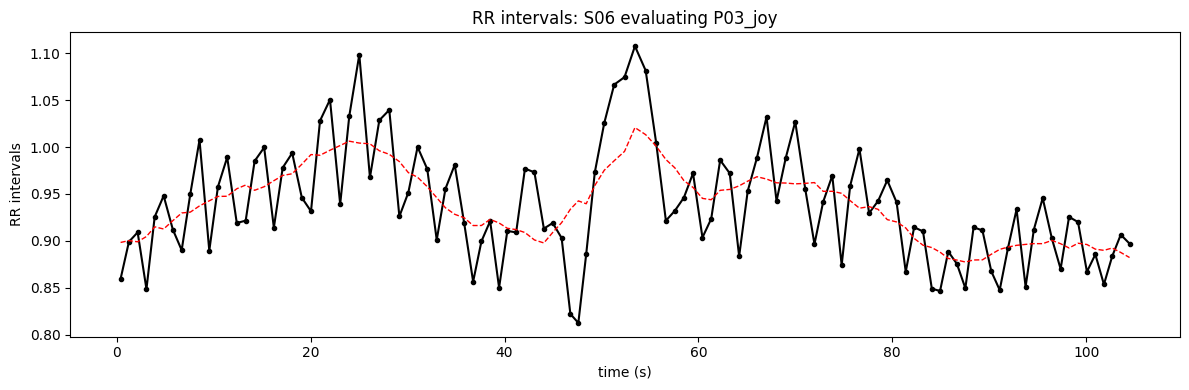

RR-intervals: [0.6835 0.6605 0.6305 0.6305 0.634  0.6215 0.634  0.6715 0.6905 0.692
 0.684  0.722  0.733  0.7435 0.7415 0.711  0.694  0.7115 0.7045 0.715
 0.715  0.679  0.6795 0.703  0.713  0.735  0.7355 0.716  0.7365 0.7535
 0.7555 0.7595 0.734  0.72   0.7335 0.7305 0.7225 0.707  0.6805 0.692
 0.684  0.6915 0.678  0.6495 0.661  0.6545 0.646  0.6405 0.6365 0.638
 0.6395 0.618  0.6195 0.631  0.631  0.637  0.631  0.614  0.622  0.6435
 0.6605 0.673  0.653  0.648  0.6655 0.65   0.6395 0.6445 0.6575 0.657
 0.629  0.6555 0.6795 0.6855 0.701  0.6795 0.649  0.6875 0.6985 0.717
 0.6785 0.6455 0.6425 0.635  0.629  0.6175 0.616  0.606  0.6325 0.683
 0.705  0.7255 0.717  0.669  0.6555 0.6585 0.654  0.641  0.632  0.6315
 0.632  0.646  0.6475 0.657  0.6605 0.6475 0.691  0.6875 0.715  0.6705
 0.674  0.6655 0.676  0.701  0.724  0.7425 0.766  0.7705 0.7215 0.7475
 0.7415 0.746  0.7445 0.759  0.7325 0.7415 0.7475 0.75   0.7605 0.768
 0.755  0.732  0.752  0.741  0.7375 0.7245 0.699  0.7105 0.718  0.7415


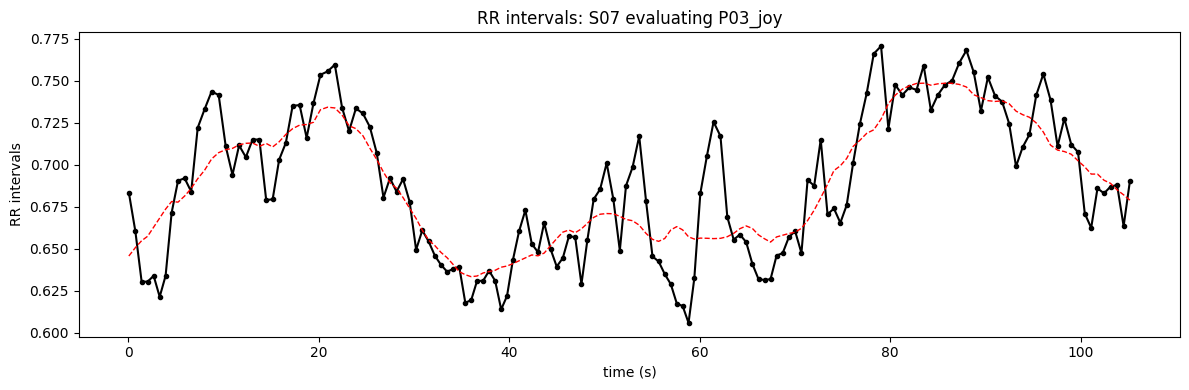

RR-intervals: [0.7055 0.766  0.741  0.717  0.708  0.697  0.6755 0.6715 0.6695 0.669
 0.661  0.653  0.65   0.6565 0.6545 0.661  0.663  0.6695 0.663  0.676
 0.6565 0.643  0.6545 0.667  0.6685 0.6675 0.687  0.6915 0.687  0.6775
 0.6865 0.6915 0.6925 0.689  0.6815 0.678  0.694  0.68   0.6745 0.675
 0.6775 0.673  0.6765 0.6675 0.6715 0.678  0.6855 0.699  0.6955 0.6945
 0.7005 0.6925 0.6885 0.693  0.6945 0.7035 0.703  0.6975 0.6975 0.6985
 0.709  0.6945 0.697  0.685  0.694  0.696  0.701  0.711  0.6915 0.6835
 0.694  0.6865 0.6855 0.682  0.688  0.695  0.69   0.686  0.678  0.6705
 0.6805 0.6775 0.678  0.6775 0.679  0.6795 0.68   0.687  0.676  0.682
 0.693  0.6845 0.69   0.6805 0.6835 0.686  0.6865 0.687  0.6875 0.6835
 0.6955 0.6965 0.6955 0.691  0.681  0.675  0.6785 0.68   0.6765 0.667
 0.6655 0.6715 0.6725 0.664  0.669  0.661  0.672  0.67   0.672  0.6715
 0.684  0.679  0.6815 0.674  0.676  0.681  0.674  0.6715 0.676  0.681
 0.6885 0.684  0.6775 0.678  0.6905 0.6945 0.6895 0.6855 0.6845 0.689

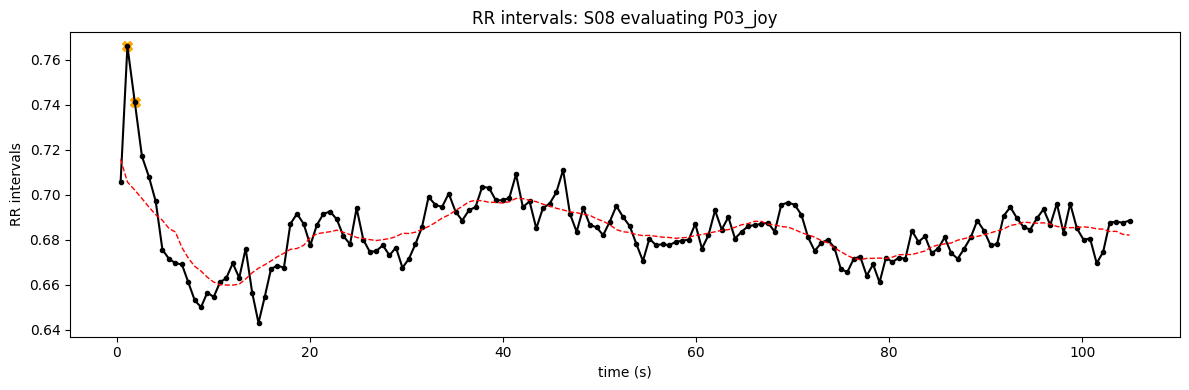

RR-intervals: [0.837     nan 0.7895 0.8195 0.896  0.924  0.951  0.9705 0.974  0.9575
 0.9435 0.9385 0.9215 0.8975 0.916  0.9235 0.858  0.88   0.8935 0.891
 0.9205 0.9095 0.9045 0.939  0.9595 0.946  0.9245 0.899  0.913  0.908
 0.8775 0.902  0.949  0.9485 0.9425 0.9355 0.8925 0.927  0.915  0.8695
 0.8815 0.8935 0.883  0.924  0.9075 0.8805 0.916  0.89   0.905  0.91
 0.868  0.893  0.885  0.852  0.88   0.891  0.8935 0.954  0.938  0.954
 0.955  0.9215 0.9075 0.9265 0.9225 0.918  0.937  0.9125 0.9195 0.9205
 0.881  0.901  0.889  0.8665 0.9045 0.9105 0.85   0.871  0.8585 0.866
 0.9    0.901  0.8925 0.9225 0.8805 0.876  0.9005 0.8885 0.8705 0.8545
 0.8405 0.8845 0.8635 0.871  0.917  0.882  0.9065 0.904  0.8795 0.9
 0.8565 0.8655 0.8725 0.8445 0.8755 0.827  0.803  0.805  0.781  0.745
 0.7705 0.7385 0.744  0.762  0.7595 0.784  0.8045 0.7735]


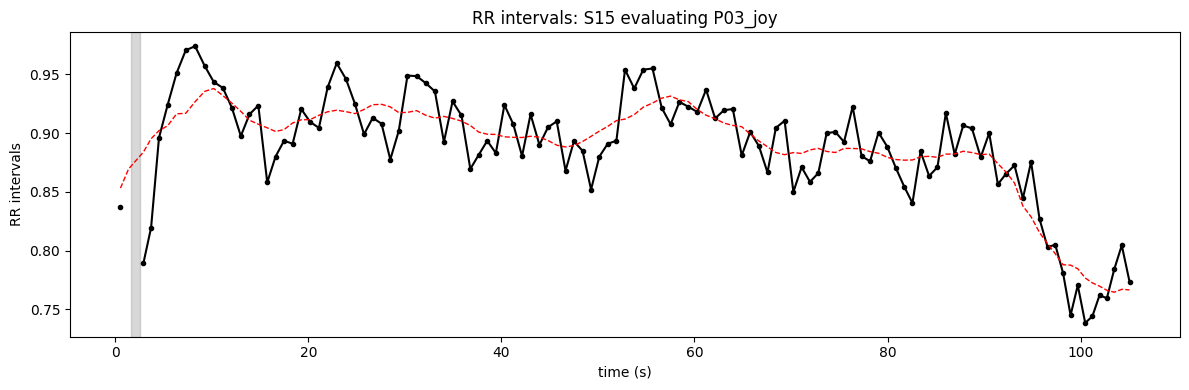

RR-intervals: [0.695  0.6875 0.6735 0.684  0.7185 0.7595 0.776  0.767  0.7535 0.716
 0.6885 0.676  0.7055 0.736  0.765  0.733  0.716  0.745  0.752  0.742
 0.7055 0.7005 0.674  0.6275 0.6135 0.605  0.613  0.6745 0.744  0.787
 0.7925 0.803  0.776  0.687  0.6625 0.6585 0.6975 0.762  0.7995 0.753
 0.746  0.763  0.7655 0.754  0.716  0.6705 0.67   0.672  0.6615 0.667
 0.729  0.762  0.74   0.6995 0.665  0.651  0.666  0.7355 0.7605 0.726
 0.735  0.7485 0.7435 0.6975 0.652  0.6365 0.615  0.6045 0.5965 0.5845
 0.597  0.635  0.7155 0.657  0.6605 0.689  0.73   0.7575 0.757  0.7535
 0.734  0.707  0.6835 0.7005 0.752  0.7825 0.755  0.7485 0.704  0.7135
 0.7205 0.7335 0.7195 0.7115 0.679  0.6895 0.755  0.7975 0.791  0.7435
 0.7085 0.723  0.723  0.7395 0.746  0.734  0.7145 0.737  0.7655 0.779
 0.786  0.78   0.7705 0.759  0.7425 0.717  0.6785 0.7155 0.781  0.852
 0.8215 0.8075 0.8205 0.793  0.7485 0.6975 0.68   0.641  0.7055 0.7485
 0.707  0.67   0.6545 0.6355 0.628  0.6085 0.6    0.6045 0.672  0.75
 0

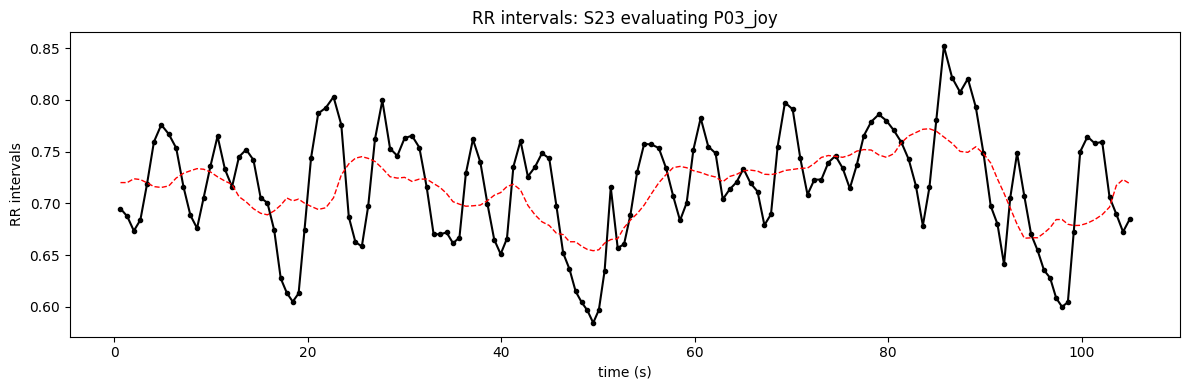

RR-intervals: [0.7935 0.7835 0.758  0.7435 0.712  0.692  0.7095 0.746  0.7565 0.7385
 0.703  0.693  0.682  0.679  0.661  0.6935 0.7315 1.002  0.95   1.045
 1.005  0.9605 0.904  0.855  0.801  0.7345 0.6935 0.6965 0.7495 0.8115
 0.974  1.0175 1.0075 0.99   0.9445 0.875  0.801  0.79   0.8025 0.81
 0.8095 0.7815 0.792  0.8155 0.8475 0.8475 0.84   0.8295 0.814  0.7705
 0.7705 0.7655 0.7575 0.765  0.7745 0.784  0.782  0.775  0.7805 0.8285
 0.908  0.9875 0.9765 0.9565 0.905  0.8575 0.786  0.739  0.726  0.738
 0.743  0.7425 0.771  0.812  0.8365 0.8235 0.8255 0.799  0.778  0.7255
 0.6975 0.698  0.7125 0.6965 0.7065 0.703  0.7295 0.7515 0.7585 0.751
 0.7645 0.771  0.7925 0.7845 0.741  0.7185 0.7195 0.7255 0.751  0.8145
 0.8605 0.845  0.7995 0.778  0.7505 0.7395 0.734  0.717  0.685  0.7015
 0.7145 0.7555 0.815  0.849  0.864  0.8485 0.847  0.8345 0.8245 0.815
 0.795  0.7685 0.755  0.7585 0.759  0.7815 0.8055 0.832  0.853  0.856
 0.8385 0.837 ]


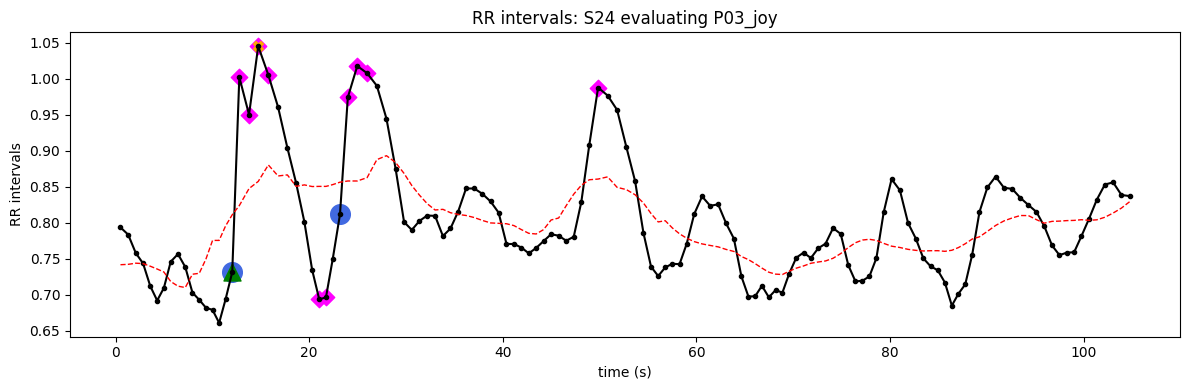

RR-intervals: [0.801  0.765  0.7495 0.7425 0.731  0.722  0.7305 0.746  0.733  0.697
 0.71   0.739  0.7585 0.7835 0.7845 0.791  0.7845 0.772  0.76   0.772
 0.77   0.776  0.7775 0.7805 0.771  0.748  0.703  0.6935 0.683  0.7035
 0.749  0.765  0.723  0.6975 0.709  0.7235 0.728  0.6965 0.717  0.728
 0.7145 0.689  0.709  0.706  0.724  0.7385 0.764  0.7665 0.7165 0.686
 0.6875 0.709  0.727  0.688  0.6715 0.6515 0.6615 0.74   0.707  0.701
 0.7365 0.7665 0.79   0.737  0.7255 0.7425 0.739  0.729  0.7025 0.717
 0.742  0.7835 0.768  0.7635 0.755  0.7455 0.7185 0.71   0.713  0.749
 0.746  0.7665 0.767  0.7345 0.6955 0.713  0.743  0.77   0.7105 0.7435
 0.77   0.7875 0.756  0.755  0.746  0.7115 0.7025 0.7235 0.7485 0.7775
 0.756  0.7565 0.7625 0.776  0.724  0.734  0.7415 0.7555 0.714  0.7065
 0.7245 0.753  0.757  0.727  0.7455 0.7655 0.762  0.701  0.71   0.71
 0.737  0.729  0.8015 0.8145 0.8215 0.7515 0.7715 0.783  0.7685 0.7215
 0.737  0.757  0.772  0.733  0.7525 0.7565 0.747  0.7245 0.7475 0.7665
 

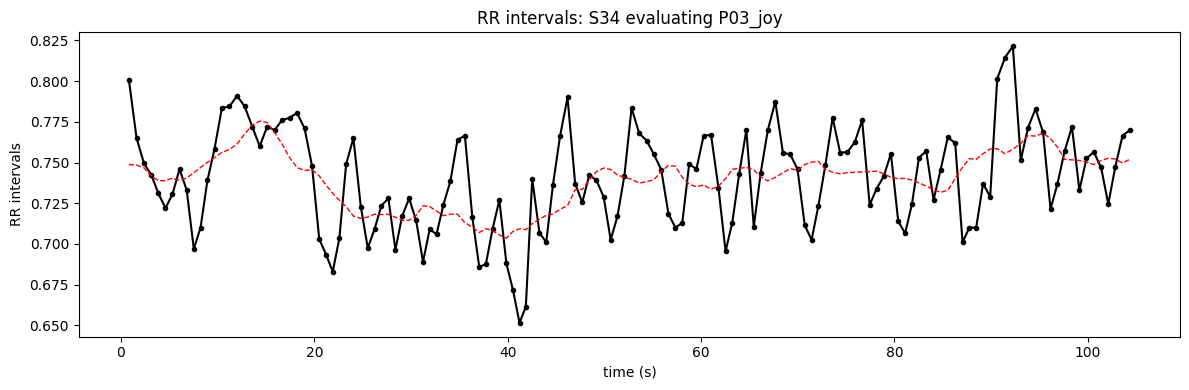

RR-intervals: [0.632  0.6205 0.614  0.6415 0.686  0.7005 0.689  0.677  0.7005 0.7185
 0.74   0.74   0.688  0.679  0.69   0.705  0.721  0.7445 0.745  0.7135
 0.717  0.733  0.7415 0.7315 0.731  0.7235 0.681  0.6835 0.6835 0.7
 0.7195 0.737  0.726  0.717  0.7265 0.731  0.74   0.7215 0.7    0.7085
 0.744  0.7725 0.7965 0.7485 0.7405 0.7565 0.7585 0.759  0.734  0.697
 0.693  0.7005 0.718  0.758  0.7595 0.736  0.7535 0.754  0.7465 0.738
 0.727  0.7325 0.734  0.7365 0.709  0.6895 0.6755 0.691  0.725  0.7285
 0.729  0.737  0.736  0.7315 0.719  0.7255 0.7315 0.7465 0.731  0.717
 0.7165 0.7345 0.749  0.7535 0.744  0.745  0.767  0.7645 0.757  0.7285
 0.737  0.7375 0.718  0.693  0.6715 0.6555 0.693  0.7315 0.771  0.7625
 0.7495 0.7675 0.791  0.78   0.7565 0.751  0.7425 0.7475 0.762  0.7495
 0.754  0.7465 0.742  0.7385 0.7675 0.778  0.789  0.7645 0.7405 0.721
 0.7255 0.7185 0.723  0.6955 0.7    0.7145 0.7435 0.76   0.7565 0.72
 0.731  0.7285 0.718  0.72   0.7015 0.699  0.708  0.728  0.7185 0.7325
 

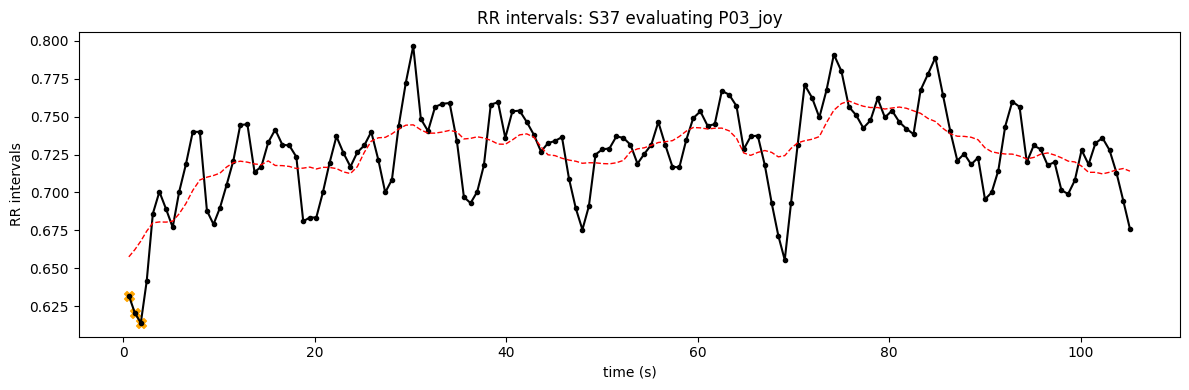

RR-intervals: [0.6425 0.647  0.645  0.6345 0.65   0.656  0.656  0.655  0.666  0.666
 0.6635 0.661  0.672  0.6665 0.6605 0.666  0.6705 0.6675 0.667  0.668
 0.669  0.6655 0.6655 0.6675 0.669  0.6715 0.6695 0.674  0.679  0.6785
 0.675  0.6765 0.6775 0.6795 0.6745 0.676  0.677  0.678  0.671  0.675
 0.6745 0.676  0.6745 0.6775 0.677  0.6735 0.674  0.6715 0.672  0.67
 0.6735 0.6755 0.6705 0.6725 0.672  0.6735 0.672  0.675  0.677  0.669
 0.676  0.6765 0.678  0.6715 0.6725 0.674  0.6725 0.669  0.6715 0.6735
 0.673  0.671  0.67   0.673  0.6735 0.6755 0.674  0.6735 0.6765 0.676
 0.669  0.6725 0.674  0.6735 0.6735 0.678  0.6825 0.6815 0.6805 0.68
 0.6745 0.6785 0.677  0.6725 0.673  0.67   0.667  0.658  0.6545 0.6535
 0.6545 0.6575 0.663  0.6585 0.66   0.6535 0.6475 0.6445 0.643  0.637
 0.6375 0.636  0.6335 0.629  0.6255 0.6185 0.613  0.6135 0.619  0.6175
 0.6305 0.6355 0.635  0.636  0.653  0.659  0.6595 0.6555 0.666  0.672
 0.6725 0.671  0.6705 0.6795 0.676  0.666  0.666  0.6775 0.6805 0.6795
 0.

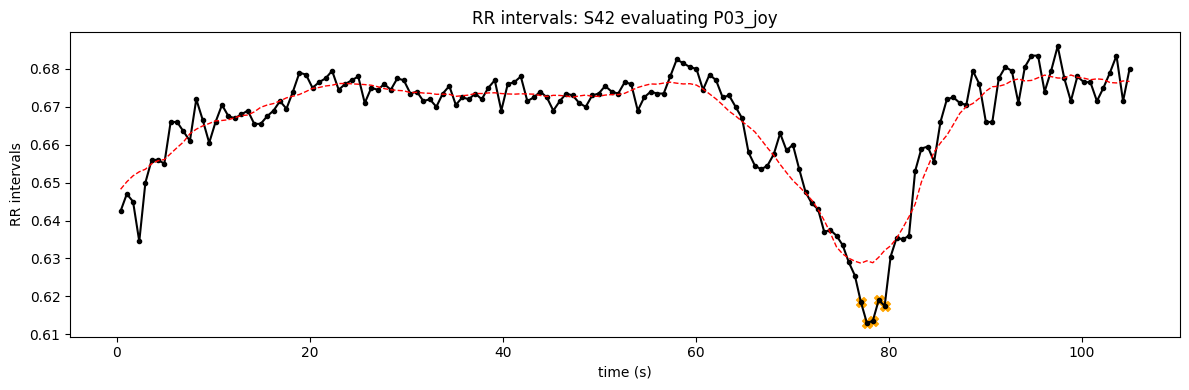

RR-intervals: [0.6815 0.6555 0.638  0.6485 0.6655 0.6575 0.6575 0.6765 0.7165 0.767
 0.7285 0.707  0.7065 0.722  0.741  0.7435 0.736  0.708  0.682  0.6735
 0.687  0.784  0.9325 0.9245 0.8905 0.8105 0.8305 0.833  0.8645 0.8405
 0.778  0.7405 0.755  0.7715 0.7885 0.778  0.7375 0.741  0.7485 0.7285
 0.6945 0.7135 0.7745 0.8405 0.777  0.746  0.7575 0.745  0.7585 0.762
 0.723  0.7015 0.707  0.7175 0.836  0.8865 0.8535 0.7945 0.825  0.8515
 0.8775 0.8445 0.7515 0.7135 0.6805 0.6585 0.6845 0.784  0.907  0.893
 0.812  0.806  0.812  0.832  0.8635 0.8115 0.7845 0.823  0.889  0.964
 0.9675 0.8845 0.7915 0.754  0.807  0.8915 0.931  0.9115 0.8005 0.7715
 0.772  0.78   0.8855 0.9205 0.8895 0.8135 0.791  0.8065 0.8235 0.868
 0.8595 0.804  0.7505 0.7785 0.8325 0.8745 0.8965 0.785  0.731  0.7265
 0.731  0.743  0.7955 0.83   0.854  0.8285 0.8075 0.831  0.8275 0.8265
 0.8455 0.8045 0.7545 0.743  0.7585 0.7995 0.9395 0.8915 0.8225 0.7925
 0.836  0.8595 0.8505]


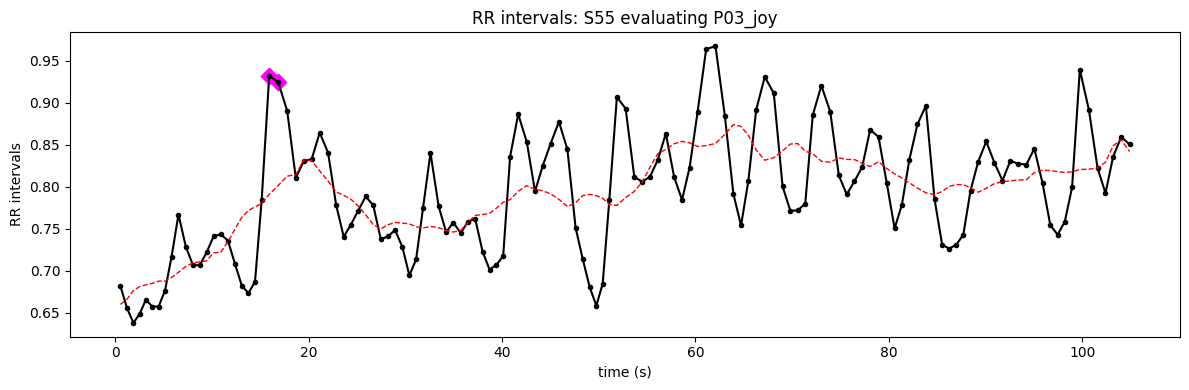

RR-intervals: [0.6885 0.68   0.685  0.726  0.754  0.7455 0.747  0.7635 0.7915 0.772
 0.7705 0.7565 0.7405 0.746  0.725  0.701  0.6885 0.6835 0.687  0.6865
 0.685  0.6775 0.692  0.708  0.7315 0.7485 0.7525 0.7915 0.851  0.878
 0.869  0.819  0.8245 0.811  0.7955 0.783  0.7575 0.748  0.7625 0.7755
 0.7605 0.7155 0.6875 0.662  0.6425 0.653  0.6575 0.6575 0.6715 0.664
 0.6585 0.6485 0.627  0.627  0.617  0.61   0.607  0.611  0.616  0.6275
 0.6425 0.6415 0.6325 0.629  0.625  0.6365 0.6705 0.6965 0.7095 0.6995
 0.7175 0.754  0.814  0.828  0.797  0.77   0.7385 0.72   0.7105 0.6975
 0.6875 0.6805 0.6915 0.7025 0.706  0.718  0.732  0.767  0.779  0.7935
 0.7795 0.785  0.7745 0.7485 0.753  0.719  0.711  0.704  0.7255 0.727
 0.7145 0.709  0.697  0.703  0.709  0.7215 0.698  0.684  0.675  0.6935
 0.7525 0.839  0.858  0.869  0.8225 0.7825 0.7545 0.7315 0.709  0.696
 0.6795 0.663  0.654  0.6375 0.638  0.6435 0.678  0.7385 0.7955 0.7825
 0.7795 0.765  0.7515 0.728 ]


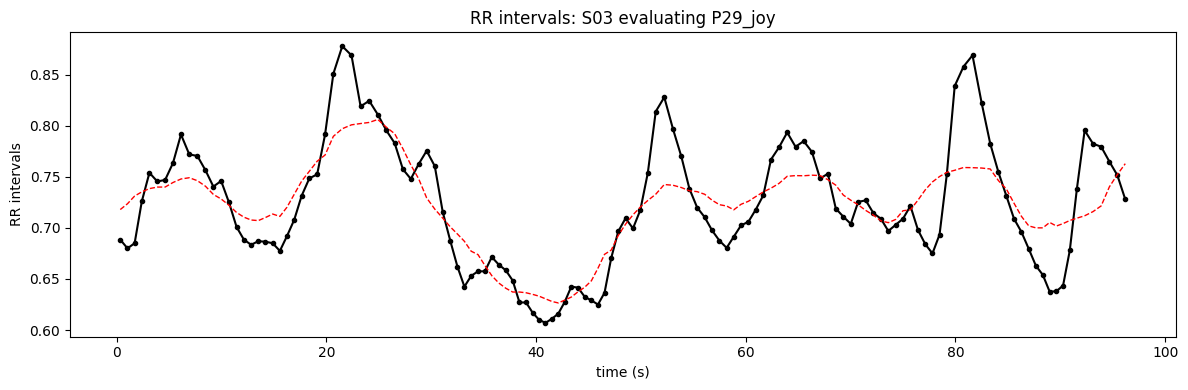

RR-intervals: [1.0055    nan    nan    nan 1.0375 1.067  0.9135 0.9395 0.975  0.924
 0.9205 1.0065 1.027  0.902  0.973  1.0225 0.953  0.955  1.024  0.984
 0.953  1.0415 1.036  0.9315 1.047  1.0115 0.9135 1.016  0.968  0.912
 1.03   1.056  0.9175 0.9705 1.0505 0.934  1.0215 1.0695 1.07   0.9205
 1.036  1.0695 0.981  0.9045 1.0055 1.0175 0.911  0.9725 1.0145 0.927
 0.901  0.995  1.0045 0.9015 1.005  0.9945 0.894  1.0105 1.0015 0.963
 0.915  1.0545 1.018  0.8985 0.9945 0.9845 0.943  0.8775 0.9635 1.006
 0.894  0.982  1.057  1.0065 0.9515 1.085  0.9525 1.0875 1.018  0.915
 1.012  1.0195 0.944  0.9815 1.0635 1.013  0.924  1.0735 0.99   0.8795
 0.9885 0.958  0.9385 1.066  1.0965 0.957  0.963  0.98   0.9395 0.9
 0.9595 0.9235 0.8945 1.009  1.0505 0.941  1.077  1.105 ]


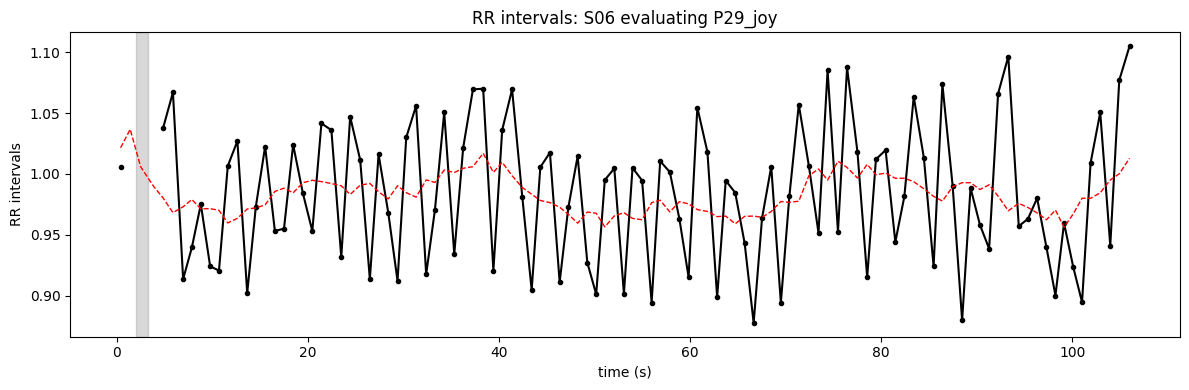

RR-intervals: [0.6875 0.685  0.6935 0.683  0.685  0.689  0.675  0.6785 0.6735 0.681
 0.684  0.6795 0.685  0.6785 0.682  0.6915 0.691  0.6815 0.6825 0.6795
 0.695  0.69   0.678  0.678  0.681  0.683  0.6905 0.7    0.6805 0.684
 0.698  0.689  0.6865 0.69   0.6955 0.701  0.6965 0.686  0.692  0.695
 0.687  0.69   0.69   0.6935 0.701  0.685  0.692  0.69   0.695  0.6875
 0.6815 0.6815 0.681  0.676  0.679  0.679  0.682  0.683  0.6825 0.6795
 0.6835 0.67   0.675  0.6815 0.677  0.6825 0.678  0.675  0.6735 0.6925
 0.679  0.671  0.675  0.689  0.6745 0.6705 0.67   0.673  0.683  0.675
 0.6715 0.674  0.684  0.678  0.6825 0.6735 0.6765 0.688  0.6805 0.674
 0.6705 0.676  0.676  0.6775 0.6815 0.681  0.698  0.6955 0.6925 0.682
 0.6885 0.6855 0.68   0.6785 0.6765 0.6795 0.678  0.678  0.6765 0.676
 0.687  0.69   0.69   0.683  0.676  0.6785 0.6935 0.6905 0.6925 0.6845
 0.694  0.699  0.6935 0.6945 0.688  0.6995 0.692  0.6965 0.6895 0.687
 0.697  0.692  0.6955 0.6885 0.692  0.6935 0.685  0.6725 0.674  0.69
 0

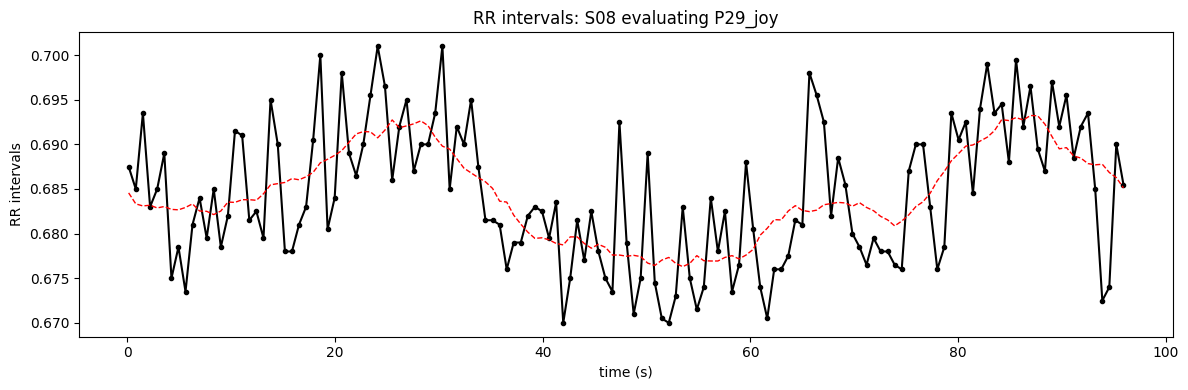

RR-intervals: [0.6765 0.678  0.6845 0.6805 0.682  0.6945 0.692  0.689  0.698  0.696
 0.6855 0.6865 0.683  0.6885 0.6845 0.681  0.688  0.6885 0.682  0.6815
 0.678  0.668  0.669  0.683  0.6755 0.68   0.6805 0.681  0.681  0.6885
 0.6825 0.6945 0.6935 0.6855 0.698  0.693  0.686  0.6965 0.6925 0.6805
 0.6895 0.686  0.6795 0.6815 0.689  0.695  0.6845 0.6945 0.694  0.685
 0.692  0.6845 0.6885 0.679  0.6915 0.6885 0.6775 0.6845 0.689  0.6815
 0.693  0.686  0.6895 0.6815 0.693  0.6875 0.6775 0.685  0.6875 0.676
 0.6875 0.683  0.6795 0.687  0.684  0.687  0.6855 0.6845 0.6895 0.6815
 0.695  0.699  0.691  0.701  0.7005 0.693  0.703  0.7    0.692  0.699
 0.702  0.6945 0.6935 0.691  0.695  0.694  0.6915 0.6935 0.6865 0.692
 0.7005 0.6825 0.692  0.6915 0.682  0.6945 0.6895 0.683  0.683  0.6855
 0.6815 0.6795 0.68   0.6855 0.6855 0.6835 0.694  0.696  0.686  0.6905
 0.689  0.6845 0.6795 0.6905 0.685  0.675  0.679  0.679  0.6775 0.674
 0.684  0.681  0.6815 0.687  0.677  0.6855 0.687  0.6775 0.682  0.682

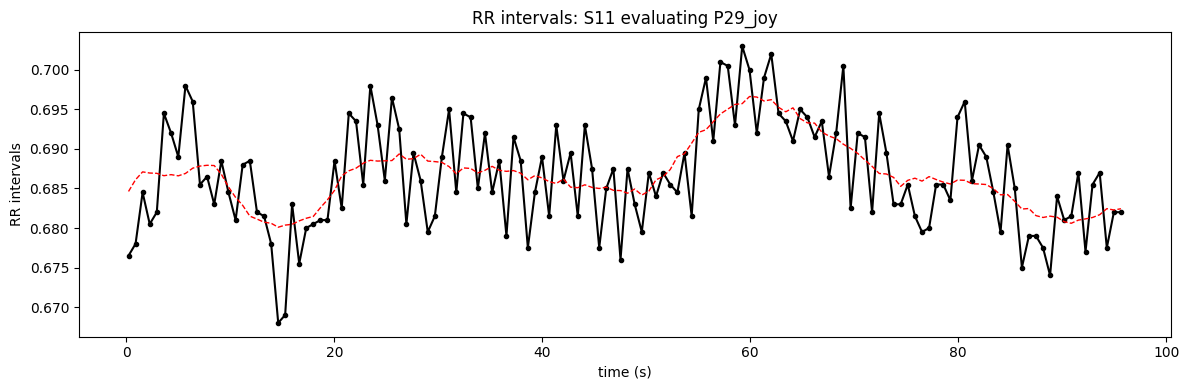

RR-intervals: [0.8885 0.8535 0.833  0.807  0.8285 0.7905 0.753  0.8165 0.8545 0.8415
 0.859  0.9025 0.8825 0.832  0.857  0.9235 0.964  1.0025 1.012  1.001
 0.9205 0.8945 0.9315 0.985  1.     0.95   0.939  0.9465 0.9905 0.999
 0.9975 0.941  0.965  0.9245 0.8945 0.8635 0.8885 0.9615 0.9955 0.9985
 0.9655 0.919  0.9565 0.9685 0.9835 0.8725 0.9095 0.9885 0.973  0.924
 0.9015 0.92   0.9185 0.8945 0.9075 0.972  0.968  0.885  0.8075 0.767
 0.759  0.962  1.013  1.0595 0.9545 0.8765 0.8015 0.8115 0.922  0.909
 0.908  0.845  0.793  0.7765 0.8445 0.935  0.9655 0.9615 0.985  0.989
 0.9885 0.93   0.854  0.8845 0.915  0.9395 0.9785 1.0305 0.981  0.883
 0.8985 0.9025 0.949  0.8825 0.9105 1.024  1.008  0.995  0.964  0.9215
 0.9155 0.904  0.851  0.8345 0.8865]


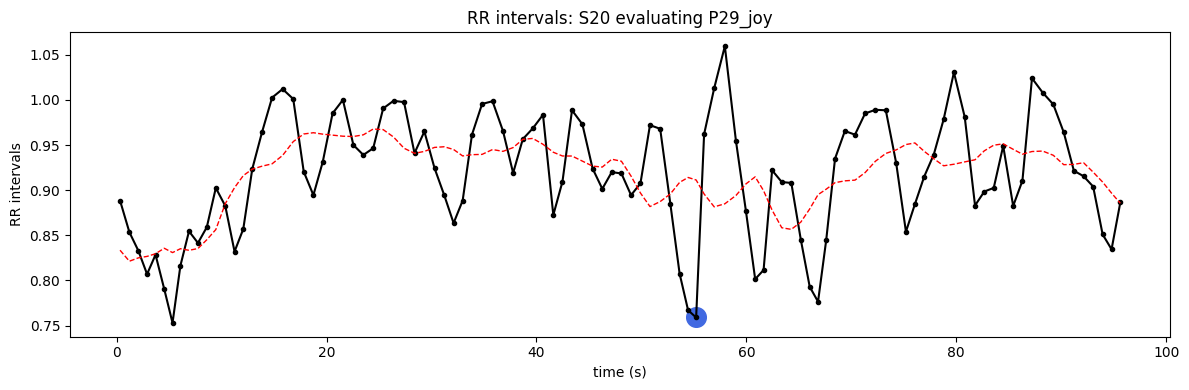

RR-intervals: [0.7075 0.686  0.7155 0.7695 0.752  0.7705 0.7345 0.723  0.699  0.739
 0.77   0.746  0.7365 0.759  0.7845 0.7285 0.7195 0.683  0.6735 0.665
 0.6685 0.6635 0.683  0.731  0.7655 0.773  0.7455 0.7435 0.745  0.7425
 0.728  0.698  0.69   0.6825 0.7045 0.753  0.7445 0.75   0.7505 0.752
 0.76   0.771  0.7555 0.741  0.7435 0.7405 0.7465 0.754  0.767  0.7535
 0.7275 0.7235 0.7425 0.7375 0.7325 0.7525 0.7705 0.785  0.766  0.77
 0.769  0.767  0.7415 0.738  0.759  0.7625 0.7555 0.6975 0.697  0.708
 0.746  0.7735 0.785  0.801  0.849  0.8105 0.799  0.819  0.8095 0.7725
 0.775  0.762  0.772  0.741  0.7515 0.7595 0.776  0.736  0.767  0.773
 0.771  0.7465 0.751  0.7335 0.703  0.675  0.672  0.696  0.6615 0.6485
 0.631  0.6595 0.662  0.655  0.669  0.6485 0.6185 0.6225 0.625  0.636
 0.638  0.63   0.617  0.6255 0.6285 0.648  0.6505 0.651  0.6725 0.69
 0.722  0.72   0.7495 0.768  0.7465 0.7205 0.718  0.712  0.728  0.739
 0.7445 0.73   0.7265]


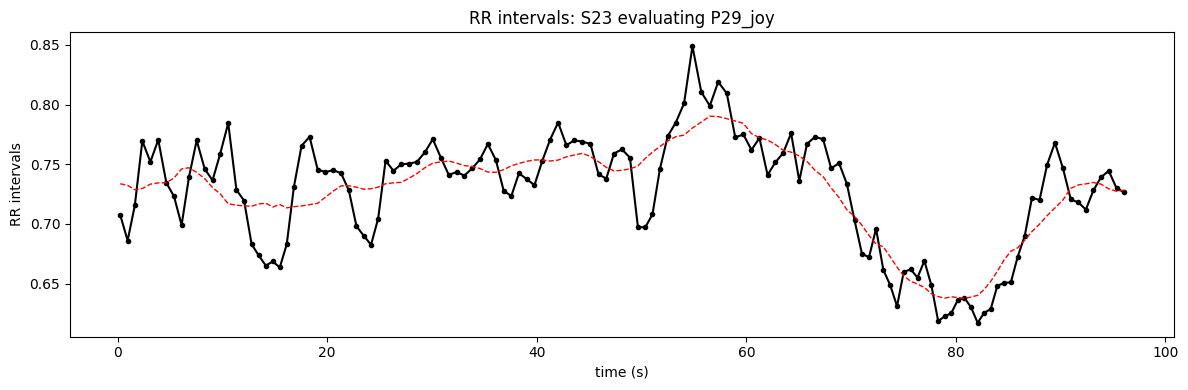

RR-intervals: [0.6405 0.629  0.6265 0.635  0.6405 0.6405 0.6475 0.657  0.664  0.6645
 0.6845 0.692  0.6945 0.697  0.689  0.687  0.686  0.677  0.688  0.6915
 0.6915 0.69   0.7015 0.7055 0.702  0.6975 0.7005 0.6995 0.695  0.6935
 0.69   0.6965 0.697  0.6865 0.6925 0.69   0.6815 0.678  0.6805 0.676
 0.676  0.6775 0.672  0.6715 0.6845 0.684  0.6825 0.6785 0.675  0.681
 0.675  0.6695 0.6675 0.666  0.6715 0.658  0.642  0.6345 0.63   0.631
 0.636  0.6455 0.6555 0.654  0.67   0.671  0.6785 0.684  0.684  0.685
 0.689  0.695  0.6945 0.694  0.6905 0.7015 0.6925 0.6995 0.69   0.6875
 0.691  0.6925 0.693  0.6975 0.7025 0.6965 0.6955 0.699  0.6925 0.693
 0.6965 0.701  0.696  0.696  0.7    0.6965 0.6875 0.685  0.685  0.686
 0.679  0.6745 0.6775 0.6795 0.6775 0.6865 0.6945 0.7005 0.6945 0.7
 0.699  0.6805 0.683  0.683  0.681  0.679  0.682  0.693  0.6865 0.677
 0.6835 0.686  0.677  0.6715 0.6705 0.6805 0.673  0.666  0.673  0.678
 0.677  0.676  0.6885 0.694  0.689  0.6825 0.6915 0.6935 0.6795 0.6745
 0.

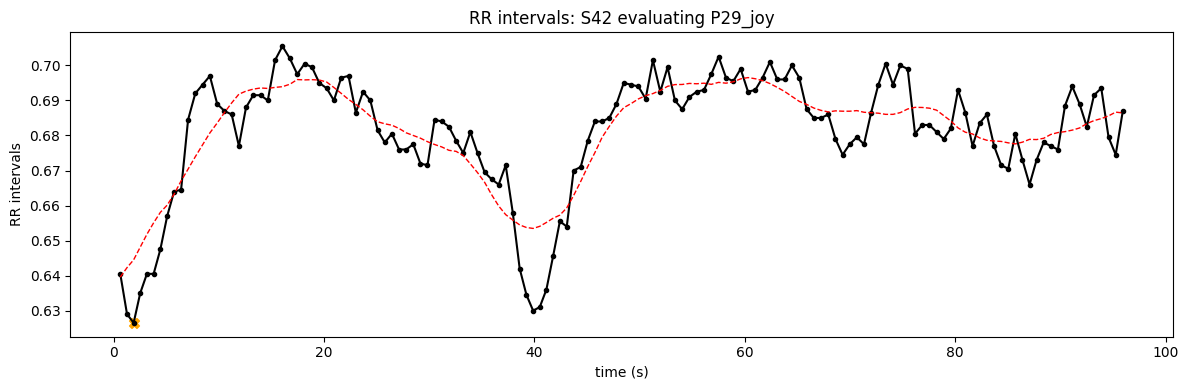

RR-intervals: [0.871  0.8995 0.9    0.863  0.807  0.847  0.857  0.882  0.8685 0.7995
 0.838  0.877  0.8825 0.8605 0.809  0.849  0.8635 0.8845 0.8615 0.814
 0.8645 0.905  0.902  0.9085 0.837  0.804  0.8435 0.871  0.914  0.9295
 0.919  0.8585 0.868  0.8965 0.9195 0.8845 0.828  0.8785 0.935  0.951
 0.9535 0.8825 0.8805 0.9095 0.9005 0.9035 0.8435 0.8785 0.933  0.933
 0.893  0.8555 0.901  0.913  0.915  0.879  0.848  0.8975 0.917  0.9235
 0.876  0.847  0.9    0.908  0.933  0.8855 0.8445 0.8755 0.887  0.8955
 0.8415 0.832  0.8775 0.917  0.9245 0.8935 0.8595 0.8935 0.8805 0.8595
 0.813  0.839  0.861  0.8885 0.85   0.8265 0.876  0.8855 0.8885 0.839
 0.8185 0.8495 0.8535 0.837  0.802  0.8435 0.863  0.8755 0.8505 0.815
 0.8745 0.8865 0.899  0.8465 0.877  0.884  0.8775 0.814  0.8035 0.849 ]


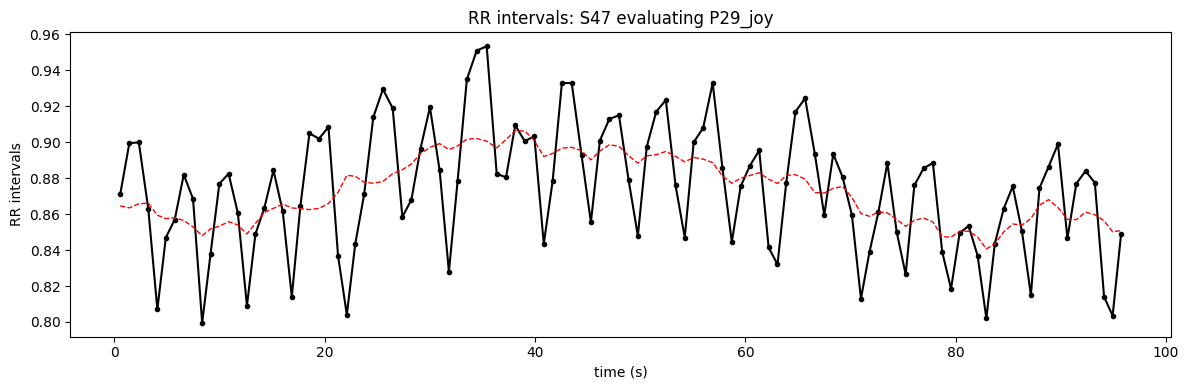

RR-intervals: [0.7115 0.6985 0.7015 0.695  0.694  0.72   0.733  0.737  0.7495 0.7475
 0.749  0.7415 0.7345 0.7455 0.7575 0.7645 0.7725 0.7855 0.77   0.7635
 0.7775 0.7735 0.7665 0.7455 0.7365 0.741  0.742  0.727  0.715  0.7265
 0.726  0.7085 0.7105 0.7115 0.7185 0.7145 0.7    0.707  0.7135 0.718
 0.71   0.7105 0.7235 0.722  0.7155 0.716  0.723  0.721  0.711  0.7255
 0.7285 0.734  0.7245 0.7285 0.7475 0.7545 0.7615 0.747  0.744  0.75
 0.744  0.725  0.7355 0.7415 0.748  0.7235 0.7185 0.724  0.726  0.7105
 0.7085 0.7175 0.7155 0.7075 0.706  0.712  0.7165 0.7175 0.719  0.729
 0.735  0.741  0.7265 0.735  0.747  0.758  0.739  0.7525 0.7545 0.7495
 0.729  0.731  0.7385 0.739  0.7125 0.707  0.7135 0.716  0.707  0.7005
 0.7115 0.7225 0.7285 0.7145 0.732  0.7395 0.737  0.735  0.73   0.743
 0.7425 0.7475 0.7365 0.751  0.7485 0.7285 0.7205 0.734  0.743  0.7465
 0.7405 0.753  0.7565 0.756  0.739  0.729  0.737  0.7275 0.732  0.721
 0.724 ]


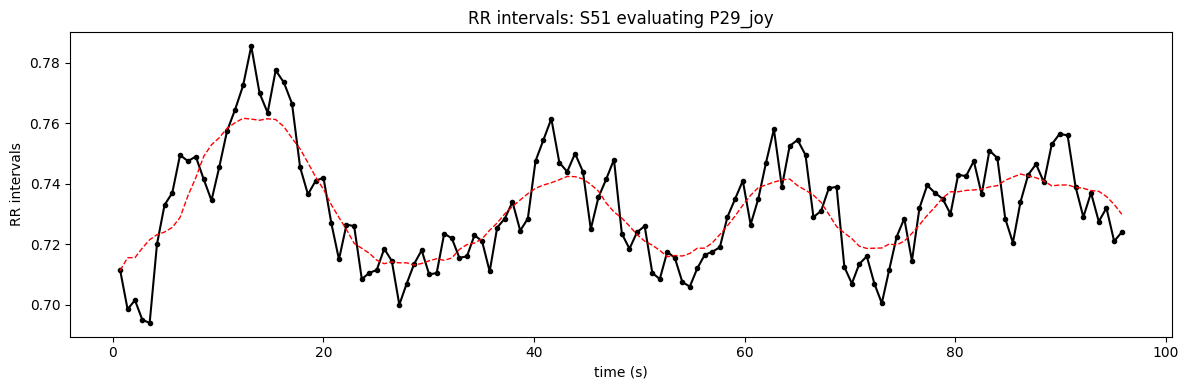

RR-intervals: [0.6955 0.6995 0.6865 0.688  0.687  0.68   0.6565 0.6685 0.667  0.6675
 0.661  0.664  0.6765 0.6805 0.6675 0.6645 0.6715 0.666  0.66   0.6545
 0.6675 0.6705 0.675  0.6625 0.6755 0.6635 0.655  0.6485 0.6575 0.647
 0.6455 0.6395 0.641  0.6425 0.631  0.6435 0.632  0.637  0.648  0.657
 0.6735 0.6745 0.6675 0.6405 0.629  0.6385 0.633  0.6385 0.631  0.641
 0.651  0.66   0.6605 0.6705 0.6455 0.6615 0.667  0.6595 0.666  0.663
 0.664  0.6555 0.6625 0.6645 0.662  0.6505 0.6575 0.667  0.6695    nan
 0.6705 0.667  0.652  0.6455 0.6575 0.6625 0.6675 0.667  0.6805 0.678
 0.6865 0.6845 0.7145 0.716  0.7065 0.6965 0.711  0.7075 0.694  0.684
 0.692  0.688  0.6795 0.6745 0.687  0.683  0.6795 0.672  0.6885 0.686
 0.687  0.6765 0.693  0.684  0.687  0.668  0.6765 0.665  0.667  0.651
 0.6595 0.659  0.666  0.6565 0.6565 0.6595 0.6635 0.654  0.6675 0.6555
 0.6535 0.64   0.6325 0.64   0.635  0.639  0.627  0.6445 0.6485 0.661
 0.653  0.657  0.662  0.661  0.647  0.637  0.628  0.6215 0.6105 0.617
 0

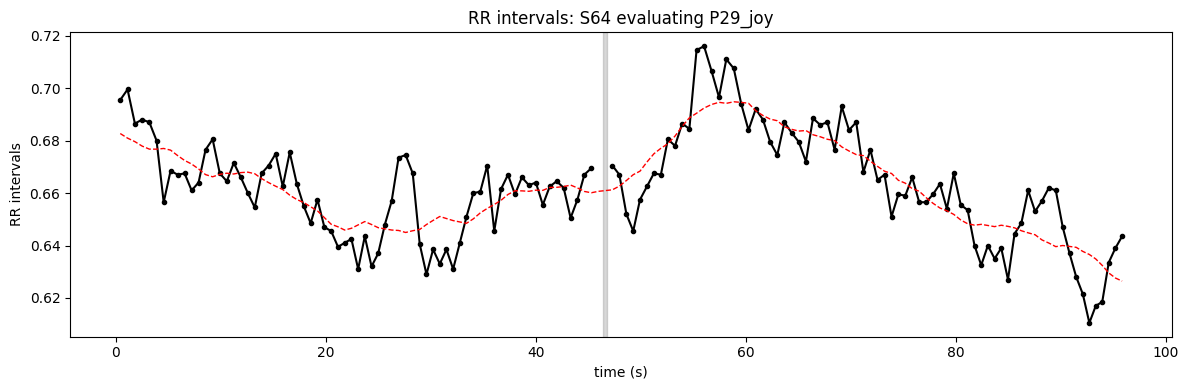

In [4]:


count = 0


for target in targets:
    for perceiver in perceivers:
        
        
        if count >= 20:
            break # I added this to not produce all plots (28 perceivers * 12 targets) otherwise the file becomes too big
        
        
        ecg_data_perceiver = load_ecg_data(os.path.join(data_folder, f"{perceiver}_{target}_peaks.json")) # load data for later (already loaded in clean_perceiver_ecg could be optimized)
        perceiver_peak_times, perceiver_time_diffs = clean_perceiver_ecg(data_folder, perceiver, target) # extract peak times and RR intervals
        
        if len(perceiver_time_diffs) == 0:
            continue # skip if no data (just in case)
        
        print(f"RR-intervals: {perceiver_time_diffs}") # print the RR intervals (could be useful to check anomalies)
        
        invalid_areas = ecg_data_perceiver.get("invalid", {}).get("ECG, X, RSPEC-R", []) # identify invalid areas

        smoothed_RR_times, smoothed_RR_values = sliding_window_mean( # smoothed RR intervals
            np.array(perceiver_peak_times), np.array(perceiver_time_diffs))
        
        
        
        # malik rule: RR-intervals differing by more than the 20 % of the next RR interval are removed.
        outlier_malik = [RR for RR in range(len(perceiver_time_diffs) - 1) if abs(perceiver_time_diffs[RR] - perceiver_time_diffs[RR + 1]) > 0.2 * perceiver_time_diffs[RR]] # -1 otherwise out of bounds?
        
        # kamath rule: R-R intervals increasing or decreasing by more than 32.5% or by more than 24.5% from the previous interval are removed.
        outlier_kamath = [RR for RR in range(len(perceiver_time_diffs) - 1) if 0 < perceiver_time_diffs[RR + 1] - perceiver_time_diffs[RR] > .325 * perceiver_time_diffs[RR] or 
                                                                                0 < (perceiver_time_diffs[RR] - perceiver_time_diffs[RR+1] > .245 * perceiver_time_diffs[RR])]
                 
        # karlsson rule: RR-intervals differing by more than the 20 % of the mean of previous and next RR-interval are removed.
        outlier_karlsson = [RR for RR in range(1, len(perceiver_time_diffs) - 1) if abs(((perceiver_time_diffs[RR - 1] + perceiver_time_diffs[RR + 1]) / 2) - perceiver_time_diffs[RR]) > 0.2 * ((perceiver_time_diffs[RR - 1] + perceiver_time_diffs[RR + 1]) / 2)]
        
        # acar rule: RR-intervals differing by more than the 20 % of the mean of last 9 RR intervals are removed.
        outlier_acar = [RR for RR in range(9, len(perceiver_time_diffs)) if abs(perceiver_time_diffs[RR] - np.mean(perceiver_time_diffs[RR-9:RR])) > 0.2 * np.mean(perceiver_time_diffs[RR-9:RR])]

        # sd rule: RR-intervals exceeding 3 SD from the mean of all RR-intervals are removed. 
        outlier_sd = [i for i in range(len(perceiver_time_diffs) -1) if abs(zscore(perceiver_time_diffs)[i]) > 3]
    
    
    
        plt.figure(figsize=(12, 4)) # create plot

        plt.plot(perceiver_peak_times, perceiver_time_diffs, color='black', linestyle='-', marker='o', markersize=3) # raw RR intervals
        plt.plot(smoothed_RR_times, smoothed_RR_values, color='red', linewidth=1, linestyle='--') # smoothed RR intervals
        for invalid in invalid_areas: # highlight invalid areas in ECG
            plt.axvspan(invalid["start"], invalid["end"], color="grey", alpha=0.3)
            
        for i in outlier_malik: # identify ectopic beats according to each rule (different color and shape)
            plt.scatter(perceiver_peak_times[i], perceiver_time_diffs[i], color='royalblue', s=200, marker='o')            
        for i in outlier_kamath:
            plt.scatter(perceiver_peak_times[i], perceiver_time_diffs[i], color='green', s=150, marker='^')
        for i in outlier_karlsson:
            plt.scatter(perceiver_peak_times[i], perceiver_time_diffs[i], color='red', s=100, marker='s')
        for i in outlier_acar:
            plt.scatter(perceiver_peak_times[i], perceiver_time_diffs[i], color='magenta', s=70, marker='D')
        for i in outlier_sd:
            plt.scatter(perceiver_peak_times[i], perceiver_time_diffs[i], color='orange', s=50, marker='X')
            
            
            
        plt.xlabel('time (s)')
        plt.ylabel('RR intervals')
        plt.title(f'RR intervals: {perceiver} evaluating {target}')

        plt.tight_layout()
        plt.show()
        
        
        
        count += 1
    if count >= 20:
        break        